# Variance Component Analysis for NIST Samples

# Similarity Index

# 1.  Load Libraries

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf


# 2. Load Data and Initial Data Wrangling

In [2]:
similarity_df = pd.read_csv("./results/NIST_SI_df.csv")
similarity_df = similarity_df.set_index('sample')
similarity_df

,1mg_1_A_1,1mg_1_A_2,1mg_1_A_3,1mg_1_B_1,1mg_1_B_2,1mg_1_B_3,1mg_1_C_1,1mg_1_C_2,1mg_1_C_3,1mg_2_A_1,...,1mg_7_C_3,1mg_8_A_1,1mg_8_A_2,1mg_8_A_3,1mg_8_B_1,1mg_8_B_2,1mg_8_B_3,1mg_8_C_1,1mg_8_C_2,1mg_8_C_3
sample,,,,,,,,,,,,,,,,,,,,,
1mg_1_A_1,1.000000,0.831003,0.821316,0.796233,0.792828,0.784605,0.763833,0.749739,0.756620,0.787309,...,0.743640,0.776177,0.776508,0.781662,0.770399,0.771676,0.759899,0.680164,0.678368,0.675971
1mg_1_A_2,0.825139,1.000000,0.809028,0.795368,0.784733,0.786278,0.763169,0.744691,0.760187,0.784001,...,0.732407,0.766909,0.765920,0.767427,0.758592,0.769942,0.751659,0.684063,0.685836,0.676697
1mg_1_A_3,0.826607,0.815671,1.000000,0.794255,0.793140,0.803587,0.770922,0.756370,0.766100,0.802031,...,0.741550,0.772648,0.767783,0.769453,0.762615,0.775297,0.753275,0.692200,0.695966,0.685956
1mg_1_B_1,0.796693,0.803740,0.793040,1.000000,0.822128,0.813250,0.761478,0.752002,0.753197,0.773927,...,0.724351,0.757018,0.754993,0.765580,0.771474,0.783852,0.761352,0.671270,0.666112,0.666971
1mg_1_B_2,0.797266,0.792236,0.788410,0.821514,1.000000,0.834051,0.768187,0.766396,0.753395,0.786000,...,0.742122,0.761124,0.761466,0.772117,0.764807,0.775759,0.750702,0.692426,0.681137,0.676491
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1mg_8_B_2,0.765644,0.766362,0.764181,0.771437,0.765394,0.775077,0.715878,0.707325,0.711190,0.753503,...,0.731217,0.773364,0.767001,0.778052,0.799662,0.960000,0.776708,0.668912,0.674864,0.666606
1mg_8_B_3,0.745821,0.740269,0.733097,0.740801,0.728574,0.730660,0.700921,0.700711,0.692477,0.737830,...,0.712538,0.762042,0.754678,0.761146,0.771471,0.769144,0.950000,0.653900,0.659970,0.650014
1mg_8_C_1,0.676097,0.681543,0.678503,0.663888,0.680875,0.670906,0.683118,0.675024,0.683882,0.669040,...,0.680441,0.661130,0.674536,0.674214,0.667392,0.668100,0.664942,0.940000,0.745297,0.754563


In [3]:
# Average each pair (AB, BA), (AC, CA), etc.
mean_df = (similarity_df + similarity_df.T) / 2

# Keep only the upper triangle (excluding the diagonal)
data_for_heatmap = mean_df.where(np.triu(np.ones(mean_df.shape), k=0).astype(bool))
# data_for_heatmap

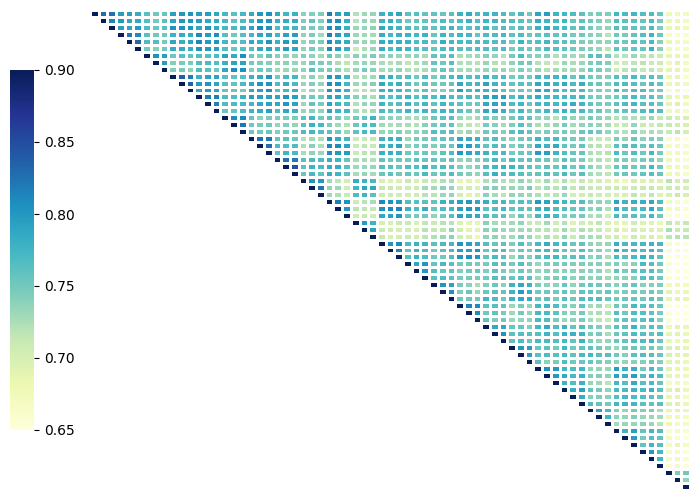

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(8, 6))

# Create axes: [left, bottom, width, height]
cbar_ax = fig.add_axes([0.05, 0.2, 0.03, 0.6])   # left side colorbar
ax = fig.add_axes([0.15, 0.1, 0.75, 0.8])        # main heatmap

sns.heatmap(
    data_for_heatmap,
    cmap="YlGnBu",
    vmin=0.65,
    vmax=0.90, 
    linewidths=1.0,
    cbar=True,
    cbar_ax=cbar_ax,
    ax=ax
)

# Remove labels on both Axis
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")


# Saves the image as a .jpg file
plt.savefig('Heatmap_of_NIST_Study.jpg')

plt.show()

In [5]:
mean_df

,1mg_1_A_1,1mg_1_A_2,1mg_1_A_3,1mg_1_B_1,1mg_1_B_2,1mg_1_B_3,1mg_1_C_1,1mg_1_C_2,1mg_1_C_3,1mg_2_A_1,...,1mg_7_C_3,1mg_8_A_1,1mg_8_A_2,1mg_8_A_3,1mg_8_B_1,1mg_8_B_2,1mg_8_B_3,1mg_8_C_1,1mg_8_C_2,1mg_8_C_3
sample,,,,,,,,,,,,,,,,,,,,,
1mg_1_A_1,1.000000,0.828071,0.823961,0.796463,0.795047,0.783600,0.763169,0.751606,0.755817,0.793572,...,0.742135,0.773177,0.770116,0.775470,0.764759,0.768660,0.752860,0.678130,0.676096,0.672004
1mg_1_A_2,0.828071,1.000000,0.812349,0.799554,0.788484,0.786769,0.764947,0.748614,0.761781,0.790715,...,0.733487,0.765709,0.760454,0.763044,0.755740,0.768152,0.745964,0.682803,0.682839,0.671853
1mg_1_A_3,0.823961,0.812349,1.000000,0.793647,0.790775,0.799401,0.768068,0.754753,0.763898,0.804621,...,0.735651,0.765576,0.757217,0.759299,0.754687,0.769739,0.743186,0.685352,0.688453,0.676600
1mg_1_B_1,0.796463,0.799554,0.793647,1.000000,0.821821,0.809759,0.761018,0.750889,0.750808,0.778505,...,0.719537,0.751568,0.745809,0.756863,0.764910,0.777645,0.751077,0.667579,0.661102,0.660881
1mg_1_B_2,0.795047,0.788484,0.790775,0.821821,1.000000,0.831565,0.767334,0.764767,0.749607,0.789571,...,0.736047,0.755903,0.751607,0.762809,0.756919,0.770577,0.739638,0.686650,0.673801,0.668108
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1mg_8_B_2,0.768660,0.768152,0.769739,0.777645,0.770577,0.779161,0.719330,0.711287,0.715842,0.764606,...,0.732582,0.774258,0.763527,0.775314,0.798801,0.960000,0.772926,0.668506,0.674181,0.663405
1mg_8_B_3,0.752860,0.745964,0.743186,0.751077,0.739638,0.739023,0.707466,0.708103,0.701368,0.752278,...,0.717448,0.765910,0.755797,0.762148,0.772444,0.772926,0.950000,0.659421,0.665891,0.652676
1mg_8_C_1,0.678130,0.682803,0.685352,0.667579,0.686650,0.675438,0.685065,0.678937,0.687620,0.680310,...,0.681684,0.662349,0.669285,0.670328,0.665044,0.668506,0.659421,0.940000,0.744896,0.750468


In [6]:
# Only Use 1st Column for this comparison (Everything is compared to 1_A_1)
df_vs_1_A_1 = mean_df['1mg_1_A_1'].reset_index()

# rename column to SI
df_vs_1_A_1 = df_vs_1_A_1.rename(columns={'1mg_1_A_1': 'Result'})


df_vs_1_A_1[['amount', 'sample', 'aliquot', 'run']] = df_vs_1_A_1['sample'].str.split('_', expand=True)

df_vs_1_A_1 = df_vs_1_A_1[['sample', 'aliquot', 'run', 'Result']]
# convert 
df_vs_1_A_1

,sample,aliquot,run,Result
0,1,A,1,1.000000
1,1,A,2,0.828071
2,1,A,3,0.823961
3,1,B,1,0.796463
4,1,B,2,0.795047
...,...,...,...,...
64,8,B,2,0.768660
65,8,B,3,0.752860
66,8,C,1,0.678130
67,8,C,2,0.676096


In [7]:
# Make sure all identifiers as categorical
df_vs_1_A_1["sample"] = df_vs_1_A_1["sample"].astype("category")
df_vs_1_A_1["aliquot"] = df_vs_1_A_1["aliquot"].astype("category")
df_vs_1_A_1["run"] = df_vs_1_A_1["run"].astype("category")

In [8]:
df_vs_1_A_1["aliquotID"] = (
    df_vs_1_A_1["sample"].astype(str)
    + "_"
    + df_vs_1_A_1["aliquot"].astype(str)
)

In [9]:
df_vs_1_A_1

,sample,aliquot,run,Result,aliquotID
0,1,A,1,1.000000,1_A
1,1,A,2,0.828071,1_A
2,1,A,3,0.823961,1_A
3,1,B,1,0.796463,1_B
4,1,B,2,0.795047,1_B
...,...,...,...,...,...
64,8,B,2,0.768660,8_B
65,8,B,3,0.752860,8_B
66,8,C,1,0.678130,8_C
67,8,C,2,0.676096,8_C


In [10]:
import statsmodels.formula.api as smf

model = smf.mixedlm(
    "Result ~ 1",
    data=df_vs_1_A_1,
    groups="sample",
    vc_formula={
        "aliquot": "0 + C(aliquotID)"
    }
)

result = model.fit(reml=True)

C:\Users\dsmal\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [19]:
#sample_var = result.cov_re.iloc[0, 0]

#aliquot_var = result.vcomp[0]

#run_var = result.scale

#total = sample_var + aliquot_var + run_var

#print(f"Sample variance  : {sample_var:.4f}")
#print(f"Aliquot variance : {aliquot_var:.4f}")
#print(f"Run variance     : {run_var:.4f}")
#print(f"Total variance   : {total:.4f}")

In [12]:
print(result.summary())

print(result.cov_re)

print(result.vcomp)

print(result.scale)


        Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: Result  
No. Observations: 69      Method:             REML    
No. Groups:       8       Scale:              0.0005  
Min. group size:  6       Log-Likelihood:     137.4284
Max. group size:  9       Converged:          Yes     
Mean group size:  8.6                                 
------------------------------------------------------
            Coef. Std.Err.    z    P>|z| [0.025 0.975]
------------------------------------------------------
Intercept   0.773    0.008 100.493 0.000  0.758  0.788
aliquot Var 0.001    0.023                            

Empty DataFrame
Columns: []
Index: []
[0.00119898]
0.0004850211085939493


In [52]:
Total_Variance =    0 + 0.0011989 + 0.000485
print('sample variance (%) = ', 100*0/Total_Variance) 
print('aliquot variance (%) = ', 100*0.00119898/Total_Variance) 
print('run variance (%) = ', 100*0.000485/Total_Variance) 

sample variance (%) =  0.0
aliquot variance (%) =  71.20256547300909
run variance (%) =  28.80218540293367


Sample variance ≈ 0
Aliquot variance ≈ 0.0012
Run (residual) variance ≈ 0.00049

In [3]:
df = pd.read_csv("./results/NIST_SI_df.csv")

y = df["biomass"]

#A = df[["temp", "rain"]]
#B = df[["ph", "nitrogen"]]

In [4]:
df


,sample,1mg_1_A_1,1mg_1_A_2,1mg_1_A_3,1mg_1_B_1,1mg_1_B_2,1mg_1_B_3,1mg_1_C_1,1mg_1_C_2,1mg_1_C_3,...,1mg_7_C_3,1mg_8_A_1,1mg_8_A_2,1mg_8_A_3,1mg_8_B_1,1mg_8_B_2,1mg_8_B_3,1mg_8_C_1,1mg_8_C_2,1mg_8_C_3
0,1mg_1_A_1,1.000000,0.831003,0.821316,0.796233,0.792828,0.784605,0.763833,0.749739,0.756620,...,0.743640,0.776177,0.776508,0.781662,0.770399,0.771676,0.759899,0.680164,0.678368,0.675971
1,1mg_1_A_2,0.825139,1.000000,0.809028,0.795368,0.784733,0.786278,0.763169,0.744691,0.760187,...,0.732407,0.766909,0.765920,0.767427,0.758592,0.769942,0.751659,0.684063,0.685836,0.676697
2,1mg_1_A_3,0.826607,0.815671,1.000000,0.794255,0.793140,0.803587,0.770922,0.756370,0.766100,...,0.741550,0.772648,0.767783,0.769453,0.762615,0.775297,0.753275,0.692200,0.695966,0.685956
3,1mg_1_B_1,0.796693,0.803740,0.793040,1.000000,0.822128,0.813250,0.761478,0.752002,0.753197,...,0.724351,0.757018,0.754993,0.765580,0.771474,0.783852,0.761352,0.671270,0.666112,0.666971
4,1mg_1_B_2,0.797266,0.792236,0.788410,0.821514,1.000000,0.834051,0.768187,0.766396,0.753395,...,0.742122,0.761124,0.761466,0.772117,0.764807,0.775759,0.750702,0.692426,0.681137,0.676491
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,1mg_8_B_2,0.765644,0.766362,0.764181,0.771437,0.765394,0.775077,0.715878,0.707325,0.711190,...,0.731217,0.773364,0.767001,0.778052,0.799662,0.960000,0.776708,0.668912,0.674864,0.666606
65,1mg_8_B_3,0.745821,0.740269,0.733097,0.740801,0.728574,0.730660,0.700921,0.700711,0.692477,...,0.712538,0.762042,0.754678,0.761146,0.771471,0.769144,0.950000,0.653900,0.659970,0.650014
66,1mg_8_C_1,0.676097,0.681543,0.678503,0.663888,0.680875,0.670906,0.683118,0.675024,0.683882,...,0.680441,0.661130,0.674536,0.674214,0.667392,0.668100,0.664942,0.940000,0.745297,0.754563
67,1mg_8_C_2,0.673824,0.679841,0.680940,0.656091,0.666464,0.663061,0.681896,0.687680,0.683627,...,0.668585,0.665905,0.666865,0.686474,0.667646,0.673498,0.671812,0.744495,0.930000,0.739473


# Protein Groups

In [26]:
summary_df = pd.read_csv("./results/NIST_summary_df.csv").set_index('Unnamed: 0')


,1mg_1_A_1,1mg_1_A_2,1mg_1_A_3,1mg_4_A_1,1mg_4_A_2,1mg_4_A_3,1mg_4_C_1,1mg_4_C_2,1mg_4_C_3,1mg_5_A_1,...,1mg_2_C_3,1mg_3_A_1,1mg_3_A_2,1mg_3_A_3,1mg_3_B_1,1mg_3_B_2,1mg_3_B_3,1mg_3_C_1,1mg_3_C_2,1mg_3_C_3
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
Protein Groups,2419,2422,2466,2517,2523,2556,2368,2327,2318,2536,...,2305,2478,2463,2471,2555,2552,2561,2387,2354,2411
Peptides,13819,13774,13956,14139,14385,14463,12916,12967,12947,14516,...,13007,14052,14078,14189,14046,14109,14125,13111,13081,13148
PSM,20265,20145,20448,20933,21307,21359,18007,18105,18240,21471,...,18865,20453,20545,20639,20810,20854,20852,18478,18520,18598


In [36]:
summary_df = pd.read_csv("./results/NIST_summary_df.csv").set_index('Unnamed: 0').T

summary_df = summary_df.reset_index()

summary_df[['amount', 'sample', 'aliquot', 'run']] = summary_df['index'].str.split('_', expand=True)


protein_groups_df = summary_df[['sample', 'aliquot', 'run', 'Protein Groups']]
protein_groups_df = protein_groups_df.rename(columns={'Protein Groups': 'Result'})

protein_groups_df


Unnamed: 0,sample,aliquot,run,Result
0,1,A,1,2419
1,1,A,2,2422
2,1,A,3,2466
3,4,A,1,2517
4,4,A,2,2523
...,...,...,...,...
64,3,B,2,2552
65,3,B,3,2561
66,3,C,1,2387
67,3,C,2,2354


In [37]:
# Make sure all identifiers as categorical
protein_groups_df["sample"] = protein_groups_df["sample"].astype("category")
protein_groups_df["aliquot"] = protein_groups_df["aliquot"].astype("category")
protein_groups_df["run"] = protein_groups_df["run"].astype("category")

In [38]:
protein_groups_df["aliquotID"] = (
    protein_groups_df["sample"].astype(str)
    + "_"
    + protein_groups_df["aliquot"].astype(str)
)

In [39]:
import statsmodels.formula.api as smf

model = smf.mixedlm(
    "Result ~ 1",
    data=protein_groups_df,
    groups="sample",
    vc_formula={
        "aliquot": "0 + C(aliquotID)"
    }
)

result = model.fit(reml=True)

In [43]:
# sample_var = result.cov_re.iloc[0, 0]

#aliquot_var = result.vcomp[0]

#run_var = result.scale

#total = sample_var + aliquot_var + run_var

#print(f"Sample variance  : {sample_var:.4f}")
#print(f"Aliquot variance : {aliquot_var:.4f}")
#print(f"Run variance     : {run_var:.4f}")
#print(f"Total variance   : {total:.4f}")

In [44]:
print(result.summary())

print(result.cov_re)

print(result.vcomp)

print(result.scale)


            Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   Result   
No. Observations:   69        Method:               REML     
No. Groups:         8         Scale:                721.5849 
Min. group size:    6         Log-Likelihood:       -362.9526
Max. group size:    9         Converged:            Yes      
Mean group size:    8.6                                      
-------------------------------------------------------------
             Coef.   Std.Err.    z    P>|z|  [0.025   0.975] 
-------------------------------------------------------------
Intercept   2433.000   20.453 118.954 0.000 2392.912 2473.088
aliquot Var 9381.257  131.306                                

Empty DataFrame
Columns: []
Index: []
[9381.25744835]
721.5848591645333


In [51]:
Total_Variance =    0 + 9381 + 721
print('sample variance (%) = ', 100*0/Total_Variance) 
print('aliquot variance (%) = ', 100*9381/Total_Variance) 
print('run variance (%) = ', 100*721/Total_Variance) 

sample variance (%) =  0.0
aliquot variance (%) =  92.86279944565433
run variance (%) =  7.137200554345674


In [45]:
print(result.vcomp)


[9381.25744835]


# Peptides

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf


In [2]:
summary_df = pd.read_csv("./results/NIST_summary_df.csv").set_index('Unnamed: 0').T

summary_df = summary_df.reset_index()

summary_df[['amount', 'sample', 'aliquot', 'run']] = summary_df['index'].str.split('_', expand=True)


peptides_df = summary_df[['sample', 'aliquot', 'run', 'Peptides']]
peptides_df = peptides_df.rename(columns={'Peptides': 'Result'})

peptides_df


Unnamed: 0,sample,aliquot,run,Result
0,1,A,1,13819
1,1,A,2,13774
2,1,A,3,13956
3,4,A,1,14139
4,4,A,2,14385
...,...,...,...,...
64,3,B,2,14109
65,3,B,3,14125
66,3,C,1,13111
67,3,C,2,13081


In [3]:
# Make sure all identifiers as categorical
peptides_df["sample"] = peptides_df["sample"].astype("category")
peptides_df["aliquot"] = peptides_df["aliquot"].astype("category")
peptides_df["run"] = peptides_df["run"].astype("category")

In [4]:
peptides_df["aliquotID"] = (
    peptides_df["sample"].astype(str)
    + "_"
    + peptides_df["aliquot"].astype(str)
)

In [5]:
import statsmodels.formula.api as smf

model = smf.mixedlm(
    "Result ~ 1",
    data=peptides_df,
    groups="sample",
    vc_formula={
        "aliquot": "0 + C(aliquotID)"
    }
)

result = model.fit(reml=True)

In [6]:
print(result.summary())

print(result.cov_re)

print(result.vcomp)

print(result.scale)


              Mixed Linear Model Regression Results
Model:               MixedLM    Dependent Variable:    Result    
No. Observations:    69         Method:                REML      
No. Groups:          8          Scale:                 11833.8862
Min. group size:     6          Log-Likelihood:        -468.5811 
Max. group size:     9          Converged:             Yes       
Mean group size:     8.6                                         
-----------------------------------------------------------------
              Coef.    Std.Err.    z    P>|z|   [0.025    0.975] 
-----------------------------------------------------------------
Intercept    13697.681  133.623 102.510 0.000 13435.785 13959.577
aliquot Var 406721.616 1383.842                                  

Empty DataFrame
Columns: []
Index: []
[406721.61588316]
11833.88622090119


In [43]:
# sample_var = result.cov_re.iloc[0, 0]

#aliquot_var = result.vcomp[0]

#run_var = result.scale

#total = sample_var + aliquot_var + run_var

#print(f"Sample variance  : {sample_var:.4f}")
#print(f"Aliquot variance : {aliquot_var:.4f}")
#print(f"Run variance     : {run_var:.4f}")
#print(f"Total variance   : {total:.4f}")

# PSMs

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf


In [2]:
summary_df = pd.read_csv("./results/NIST_summary_df.csv").set_index('Unnamed: 0').T

summary_df = summary_df.reset_index()

summary_df[['amount', 'sample', 'aliquot', 'run']] = summary_df['index'].str.split('_', expand=True)


PSM_df = summary_df[['sample', 'aliquot', 'run', 'PSM']]
PSM_df = PSM_df.rename(columns={'PSM': 'Result'})

PSM_df


Unnamed: 0,sample,aliquot,run,Result
0,1,A,1,20265
1,1,A,2,20145
2,1,A,3,20448
3,4,A,1,20933
4,4,A,2,21307
...,...,...,...,...
64,3,B,2,20854
65,3,B,3,20852
66,3,C,1,18478
67,3,C,2,18520


In [3]:
# Make sure all identifiers as categorical
PSM_df["sample"] = PSM_df["sample"].astype("category")
PSM_df["aliquot"] = PSM_df["aliquot"].astype("category")
PSM_df["run"] = PSM_df["run"].astype("category")

In [4]:
PSM_df["aliquotID"] = (
    PSM_df["sample"].astype(str)
    + "_"
    + PSM_df["aliquot"].astype(str)
)

In [5]:
import statsmodels.formula.api as smf

model = smf.mixedlm(
    "Result ~ 1",
    data=PSM_df,
    groups="sample",
    vc_formula={
        "aliquot": "0 + C(aliquotID)"
    }
)

result = model.fit(reml=True)

In [6]:
print(result.summary())

print(result.cov_re)

print(result.vcomp)

print(result.scale)


              Mixed Linear Model Regression Results
Model:               MixedLM    Dependent Variable:    Result    
No. Observations:    69         Method:                REML      
No. Groups:          8          Scale:                 20044.2048
Min. group size:     6          Log-Likelihood:        -495.5487 
Max. group size:     9          Converged:             Yes       
Mean group size:     8.6                                         
-----------------------------------------------------------------
               Coef.    Std.Err.   z    P>|z|   [0.025    0.975] 
-----------------------------------------------------------------
Intercept     19928.493  262.407 75.945 0.000 19414.185 20442.800
aliquot Var 1577035.783 4100.573                                 

Empty DataFrame
Columns: []
Index: []
[1577035.78290781]
20044.20483632016


In [43]:
# sample_var = result.cov_re.iloc[0, 0]

#aliquot_var = result.vcomp[0]

#run_var = result.scale

#total = sample_var + aliquot_var + run_var

#print(f"Sample variance  : {sample_var:.4f}")
#print(f"Aliquot variance : {aliquot_var:.4f}")
#print(f"Run variance     : {run_var:.4f}")
#print(f"Total variance   : {total:.4f}")